<a href="https://colab.research.google.com/github/StoyacoV/InvestigaciondeOperaciones/blob/main/Networkx_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color="purple">**Tutorial Networkx 1.**

## <font color="gray"> Resolucion de problemas con Networkx : Vega Benavides Axelle Stoyacovick.

Queremos resolver 3 ejercicios del curso de Investigacion de Operaciones, en concreto sobre los problemas; del árbol de expansión mínima, de la ruta más corta y del flujo máximo.
Para esto estaremos utilizando ademas de python, la libreria NetworkX.

Antes de definir cada uno de los algoritmos, veremos la importacion y grafica de cada uno de los ejercicios.

Empezando por la importacion simple y directa de nuestra librerias.

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

## <font color="yellow"> EJERCICIO 1.

Para el ejercicio 1 tenemos una red NO dirigida, la cual podremos graficar haciendo uso de la funcion simple $MultiGraph$, ademas crearemos nuestros nodos directos con una lista de arcos en lugar de definirlos.

NOTA: como hay nodos con 2 aristas con pesos diferentes, simplificamos los 2 pesos al menor y eliminamos la conexion de mayor peso.

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G=nx.Graph()

list = [
    (1, 2, 5),
    (1, 3, 1),
    (2, 4, 7),
    (2, 5, 1),
    (2, 6, 6),
    (3, 2, 2),
    (3, 4, 6),
    (3, 5, 7),
    (4, 6, 4),
    (4, 7, 6),
    (5, 4, 3),
    (5, 6, 5),
    (5, 7, 9),
    (6, 7, 2),
]

Una vez creada nuestra red, $Graph$ justo nos permite crear una lista que indique las conexiones de arco y peso en ese orden. Teniendo que de $(a,b,c)$ en nuestra lista, el orden de a,b indicaran la conexion y direccion del arco, por ultimo c solamente indicara el peso.

Ademas usaremos `add_weighted_edges_from` para añadir las aristas al grafo, recordando que estoy re nombrando el atributo weight y en caso de no ponerlo o mencionarlo tendra ese mismo nombre.

**POS**

Este diccionario calcula las coordenadas (x, y) de cada nodo para que el grafo se vea "bonito" al dibujarlo. Devuelve un diccionario con esta forma:

`{
    1: [x1, y1],
    2: [x2, y2],
    3: [x3, y3],
    4: [x4, y4],
    5: [x5, y5],
}`

Ahora si utilizaramos `spring_layout`, imagina que los nodos son bolitas y los arcos son "resortes", entonces la funcion hace que las bolitas se empujen y los resortes las jalan hasta que el sistema se estabiliza en un equilibrio. El resultado es un dibujo donde los nodos muy conectados quedan cerca, los nodos poco relacionados se alejan y se minimizan los cruces de aristas.

Es el unico modelo que mencionare, pero esa forma de interpretar la fisica entre nodos y arcos puede ser de diferentes formas como; circulares, posiciones aletorias, circulos concentricos, etc.

EN NUESTRO CASO SOLO UTILIZAMOS **POSICIONES MANUALES**, asi evitamos se entrelacen y le damos el mismo aspecto que el del ejemplo.

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.MultiGraph()

list = [
    (1, 2, 5),
    (1, 3, 1),
    (2, 4, 7),
    (2, 5, 1),
    (2, 6, 6),
    (3, 2, 2),
    (3, 4, 6),
    (3, 5, 7),
    (4, 6, 4),
    (4, 7, 6),
    (5, 4, 3),
    (5, 6, 5),
    (5, 7, 9),
    (6, 7, 2),
]

G.add_weighted_edges_from(list, weight="capacidad")

pos = {
    1: (0, 0.5),
    2: (1, 1),
    3: (1, 0),
    4: (2, 0.5),
    5: (3, 0),
    6: (3, 1),
    7: (4, 0.5)
}

Con eso definido, ya podemos graficar y dar solucion al grafo pero como quiero hacerlo al mismo tiempo primero explicare la forma de graficarlo y al final el metodo de solucion.

**Creación del lienzo**

La instrucción `plt.figure(figsize=(12, 8))` Al crear la figura antes de cualquier `draw_*`, todas las capas que se dibujen después (nodos, etiquetas, aristas grises, aristas rojas, pesos) se superpondrán en el mismo lienzo, respetando el orden en que se ejecutan.

**Dibujo de los nodos**

El bloque `nx.draw_networkx_nodes(G, pos, node_color="#FFAA00", node_size=800)` se encarga de colocar únicamente los nodos del grafo G en las coordenadas indicadas por el diccionario POS. El parámetro `node_color="#FFAA00"` pinta cada nodo, y `node_size=800` define el área del círculo en puntos cuadrados, de modo que los nodos sean visibles y no queden diminutos. Esta función no dibuja aristas ni etiquetas: solo los círculos. Si quisieras cambiar el estilo, podrías usar `node_shape="s"` para cuadrados, añadir `edgecolors="black"` para un borde negro o `alpha=0.8` para dar transparencia. Separar el dibujo de nodos del de aristas es útil porque permite controlar cada capa por independiente.

**Etiquetas de los nodos**

Inmediatamente después, `nx.draw_networkx_labels(G, pos, font_weight="bold")` escribe el identificador de cada nodo (1, 2, 3, …, 7) justo encima de su posición. El argumento `font_weight="bold"` hace que el texto aparezca en negrita. Esta función toma como referencia el mismo diccionario POS, así que las etiquetas caen exactamente en el centro de cada círculo dibujado antes. Otros parámetros que acepta son `font_size` para agrandar o reducir el número, `font_color` para cambiar el color del texto y `font_family` para elegir la tipografía.

**Aristas del grafo original en gris**

El primer `nx.draw_networkx_edges(G, pos, edge_color="lightgray", width=2, connectionstyle="arc3,rad=0.1")` dibuja **todas las aristas del grafo original** con un trazo gris claro y grosor 2. La idea es mostrar el grafo completo como contexto de fondo, de manera que luego el árbol mínimo resalte sobre él. El parámetro clave aquí es `connectionstyle="arc3,rad=0.1"`, que hace que cada arista se curve ligeramente en lugar de ser una línea recta. Esto es especialmente útil en un `MultiGraph`, donde puede haber dos aristas entre los mismos nodos (por ejemplo entre 2 y 6, o entre 3 y 4): si ambas fueran rectas se superpondrían y parecerían una sola. Al curvarse, se distinguen visualmente. El valor `rad=0.1` controla cuánto se arquea; valores mayores producen curvas más pronunciadas.

**Aristas del árbol mínimo en rojo**

Después viene `nx.draw_networkx_edges(T, pos, edge_color="red", width=4)`, que dibuja **solo las aristas del árbol de expansión mínima** `T`, en color rojo y con un grosor de 4, el doble que las grises. Como esta llamada se ejecuta después de la anterior, las aristas rojas se pintan **encima** de las grises, de modo que el árbol queda perfectamente visible sobre el entramado original. Este es el patrón clásico de visualización: primero el fondo (grafo completo en gris) y luego el resultado destacado (MST en rojo). Si quisieras otro color, bastaría con cambiar `"red"` por cualquier nombre o código hexadecimal; y si quisieras líneas discontinuas, añadirías `style="dashed"`.

**Construcción del diccionario de etiquetas del árbol**

El bloque `tree_labels = {}` seguido del bucle `for u, v, key, data in T.edges(keys=True, data=True): tree_labels[(u, v)] = data["capacidad"]` prepara la información que se mostrará como texto sobre las aristas rojas. La función `T.edges(keys=True, data=True)` recorre cada arista del árbol y devuelve cuatro cosas: el nodo origen `u`, el nodo destino `v`, la clave `key` (necesaria porque `T` proviene de un multigrafo) y el diccionario `data` con los atributos, entre ellos `"capacidad"`. El bucle guarda en `tree_labels` una entrada por arista, usando la tupla `(u, v)` como clave y el peso como valor.

**Etiquetas de peso sobre las aristas del árbol**

Finalmente, `nx.draw_networkx_edge_labels(T, pos, edge_labels=tree_labels, font_color="blue", font_size=12, label_pos=0.5, rotate=False)` escribe el peso de cada arista del árbol justo encima de ella. El parámetro `edge_labels=tree_labels` le pasa el diccionario construido en el paso anterior, `font_color="blue"` pinta el número en azul para contrastar con el rojo de la línea, y `font_size=12` fija un tamaño de letra legible. `label_pos=0.5` coloca la etiqueta en el punto medio de la arista (0 sería el origen, 1 el destino), y `rotate=False` impide que el texto gire siguiendo la inclinación de la línea, lo que mantiene los números siempre horizontales y fáciles de leer.

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.MultiGraph()

list = [
    (1, 2, 5),
    (1, 3, 1),
    (2, 4, 7),
    (2, 5, 1),
    (2, 6, 6),
    (3, 2, 2),
    (3, 4, 6),
    (3, 5, 7),
    (4, 6, 4),
    (4, 7, 6),
    (5, 4, 3),
    (5, 6, 5),
    (5, 7, 9),
    (6, 7, 2),
]

G.add_weighted_edges_from(list, weight="capacidad")

pos = {
    1: (0, 0.5),
    2: (1, 1),
    3: (1, 0),
    4: (2, 0.5),
    5: (3, 0),
    6: (3, 1),
    7: (4, 0.5)
}

plt.figure(figsize=(12, 8))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color="#FFAA00",
    node_size=800
)

nx.draw_networkx_labels(
    G,
    pos,
    font_weight="bold"
)

nx.draw_networkx_edges(
    G,
    pos,
    edge_color="lightgray",
    width=2,
    connectionstyle="arc3,rad=0.1"
)

nx.draw_networkx_edges(
    T,
    pos,
    edge_color="red",
    width=4
)

tree_labels = {}

for u, v, key, data in T.edges(keys=True, data=True):
    tree_labels[(u, v)] = data["capacidad"]

nx.draw_networkx_edge_labels(
    T,
    pos,
    edge_labels=tree_labels,
    font_color="blue",
    font_size=12,
    label_pos=0.5,
    rotate=False
)

### <font color="cyan"> ARBOL DE EXPANSION MINIMA.

Para solucionar este ejercicio utilizaremos la funcion `minimum_spanning_tree(G, weight, algorithm)` que devuelve un subgrafo que conecta todos los nodos

con el coste total mínimo y sin ciclos.

Parámetros:

`weight="capacidad"` : usa ese atributo como coste.

`algorithm="kruskal"` : también puedes usar "prim" o "boruvka".

El resultado T es otro grafo (no modifica G). Recordando que en multigrafos Kruskal/Prim eligen la arista de menor peso entre cada par, asi que en ejemplos como este donde tenemos 2 aristas conectadas a un nodo no hay problema para la solucion.

Algunas funciones extras pueden ser:

- `nx.minimum_spanning_edges(G, weight=...)` : devuelve solo las aristas, útil para listarlas.

- `T.number_of_edges()` : normalmente n_nodos - 1 si el grafo es conexo.

- `nx.is_tree(T)` : verifica que sea árbol, con este podriamos verificar soluciones.

Al final, para imprimir nuestros resultados tendremos
`T.edges(keys=True, data=True)` devuelve tuplas `(u, v, key, data)`:

- u, v → nodos extremos.
- key → identificador de la arista (importante en multigrafos).
- data → diccionario de atributos, aquí {"capacidad": ...}.

Si el grafo fuera simple, keys=True no aplicaría. El bucle acumula el peso total del árbol.

Variantes:

- `T.edges(data=True)` → sin key, solo 3 elementos.

- `T.edges()` → solo pares (u, v).

- `T.degree(nodo)` → grado de un nodo.

NOTA: hay un arco sin peso, es de la conexion entre 2 y 5 solo que al ser largo no lo dibujo con curva.

ÁRBOL DE EXPANSIÓN MÍNIMA
1 - 3 : 1
2 - 5 : 1
2 - 3 : 2
4 - 5 : 3
4 - 6 : 4
6 - 7 : 2
Peso total: 13


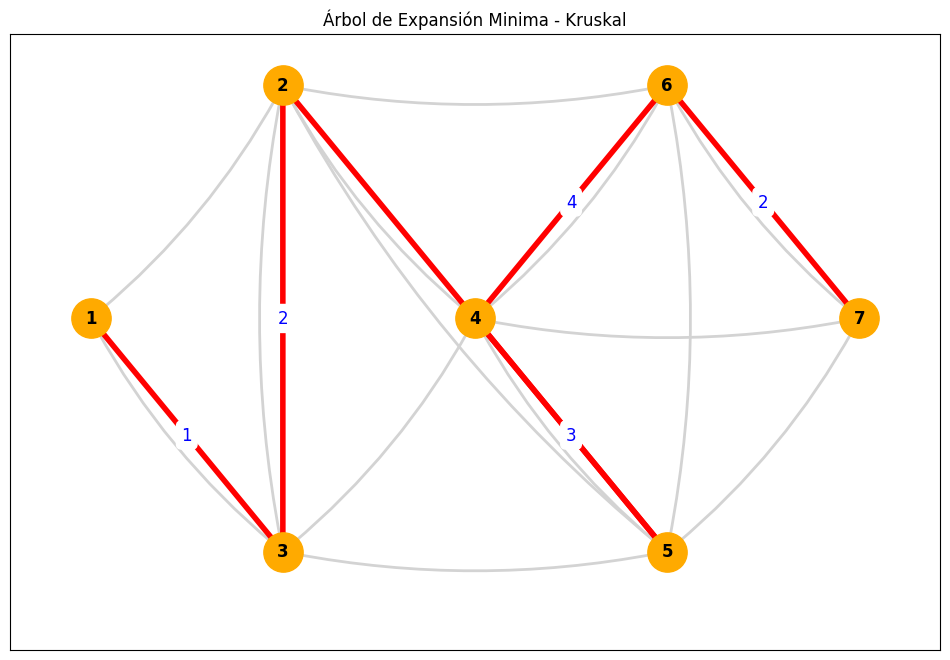

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.MultiGraph()

list = [
    (1, 2, 5),
    (1, 3, 1),
    (2, 4, 7),
    (2, 5, 1),
    (2, 6, 6),
    (3, 2, 2),
    (3, 4, 6),
    (3, 5, 7),
    (4, 6, 4),
    (4, 7, 6),
    (5, 4, 3),
    (5, 6, 5),
    (5, 7, 9),
    (6, 7, 2),
]

G.add_weighted_edges_from(list, weight="capacidad")

pos = {
    1: (0, 0.5),
    2: (1, 1),
    3: (1, 0),
    4: (2, 0.5),
    5: (3, 0),
    6: (3, 1),
    7: (4, 0.5)
}


T = nx.minimum_spanning_tree(
    G,
    weight="capacidad",
    algorithm="kruskal"
)

print("ÁRBOL DE EXPANSIÓN MÍNIMA")

peso_total = 0

for u, v, key, data in T.edges(keys=True, data=True):
    peso = data["capacidad"]
    print(f"{u} - {v} : {peso}")
    peso_total += peso

print(f"Peso total: {peso_total}")

plt.figure(figsize=(12, 8))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color="#FFAA00",
    node_size=800
)

nx.draw_networkx_labels(
    G,
    pos,
    font_weight="bold"
)

nx.draw_networkx_edges(
    G,
    pos,
    edge_color="lightgray",
    width=2,
    connectionstyle="arc3,rad=0.1"
)

nx.draw_networkx_edges(
    T,
    pos,
    edge_color="red",
    width=4
)

tree_labels = {}

for u, v, key, data in T.edges(keys=True, data=True):
    tree_labels[(u, v)] = data["capacidad"]

nx.draw_networkx_edge_labels(
    T,
    pos,
    edge_labels=tree_labels,
    font_color="blue",
    font_size=12,
    label_pos=0.5,
    rotate=False
)

plt.title("Árbol de Expansión Minima - Kruskal")
plt.show()

## <font color="yellow"> EJERCICIO 2.

Para el ejercicio 2 tenemos la misma red anterior pero dirigida, la cual podremos graficar haciendo uso de la funcion $DiGraph$ y creando una red "G" a la cual pasaremos una lista de nodos.

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G=nx.DiGraph()
G.add_nodes_from([1,2,3,4,5,6,7])

Una vez creados nuestros nodos, $DiGraph$ justo nos permite crear una lista que indique las conexiones de arco y peso de igual manera que $MultiGraph$.

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G=nx.DiGraph() # Red dirigida
G.add_nodes_from([1,2,3,4,5,6,7])

list = [
    (1, 2, 5),
    (1, 3, 1),  # 1 -> 3 peso: 1
    (1, 5, 4),
    (2, 4, 7),
    (2, 5, 1),
    (2, 6, 6),
    (3, 2, 2),
    (3, 4, 6),
    (3, 5, 7),
    (4, 3, 7),
    (4, 6, 4),
    (4, 7, 6),
    (5, 4, 3),
    (5, 6, 5),
    (5, 7, 9),
    (6, 2, 6),
    (6, 7, 2),
]

Ahora utilizaremos `"addweightededgesfrom"` el cual es un método de NetworkX que añade múltiples aristas con peso al grafo de una sola vez. Teniendo 3 atributos $(A,B,C)$ los cuales representan: (posibilidad de pasar una lista, nombre del tercer atributo "c" de nuestra lista de arcos, atributos extra que se añaden a todas las aristas).

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G=nx.DiGraph() # Red dirigida
G.add_nodes_from([1,2,3,4,5,6,7])

list = [
    (1, 2, 5),
    (1, 3, 1),  # 1 -> 3 peso: 1
    (1, 5, 4),
    (2, 4, 7),
    (2, 5, 1),
    (2, 6, 6),
    (3, 2, 2),
    (3, 4, 6),
    (3, 5, 7),
    (4, 3, 7),
    (4, 6, 4),
    (4, 7, 6),
    (5, 4, 3),
    (5, 6, 5),
    (5, 7, 9),
    (6, 2, 6),
    (6, 7, 2),
]

G.add_weighted_edges_from(list, weight='capacidad')

Una vez hecho eso, ya tenemos nuestra red y podriamos directamente graficarla, pero visualmente es preferible se vean los pesos de cada arco. Entonces utilizaremos;

**1- `POS`**

EN NUESTRO CASO SOLO UTILIZAMOS **POSICIONES MANUALES**, asi evitamos se entrelacen y le damos el mismo aspecto que el del ejemplo.

**2- `edge_labels`**

Recorre todas las aristas del grafo y extrae el valor del atributo 'capacidad' de cada una. Devuelve un diccionario con esta forma:

{
    (1, 2): 8,
    (1, 3): 14,
    (1, 5): 4,
    (2, 3): 5,
    (3, 2): 10,
    (2, 4): 7,
    ...
}

Es exactamente el formato que necesita `nx.draw_networkx_edge_labels()` para dibujar las etiquetas sobre las aristas. Esa funcion espera un diccionario `{(u,v): texto}` y esa es la forma "reducirla" de hacerlo.

Tambien podiamos hacerlo "manual" con un ciclo de la forma:

`edge_labels = {}
for u, v, data in G.edges(data=True):
    edge_labels[(u, v)] = data['capacidad']`

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
G.add_nodes_from([1,2,3,4,5,6,7])

list = [
    (1, 2, 5),
    (1, 3, 1),  # 1 -> 3 peso: 1
    (1, 5, 4),
    (2, 4, 7),
    (2, 5, 1),
    (2, 6, 6),
    (3, 2, 2),
    (3, 4, 6),
    (3, 5, 7),
    (4, 3, 7),
    (4, 6, 4),
    (4, 7, 6),
    (5, 4, 3),
    (5, 6, 5),
    (5, 7, 9),
    (6, 2, 6),
    (6, 7, 2),
]

G.add_weighted_edges_from(list, weight='capacidad')

pos = {
    1: (0, 0.5),
    2: (1, 1),
    3: (1, 0),
    4: (2, 0.5),
    5: (3, 0),
    6: (3, 1),
    7: (4, 0.5)
}

edge_labels = nx.get_edge_attributes(G, 'capacidad')

El ultimo paso, sera graficarlo; en este caso pasaremos nuestros nodos, edges (arcos) y los labels (las marcas de peso) a las funciones de dibujo `draw_networkx`, hay un detalle tambien y es que al tener dos arcos entre 2 nodos con diferentes pesos al graficarlo uno se sobrepone al otro

Como extra añadimos un titulo y tamaño a la imagen haciendo uso de plt.

Text(0.5, 1.0, 'Grafo: Flujo Máximo')

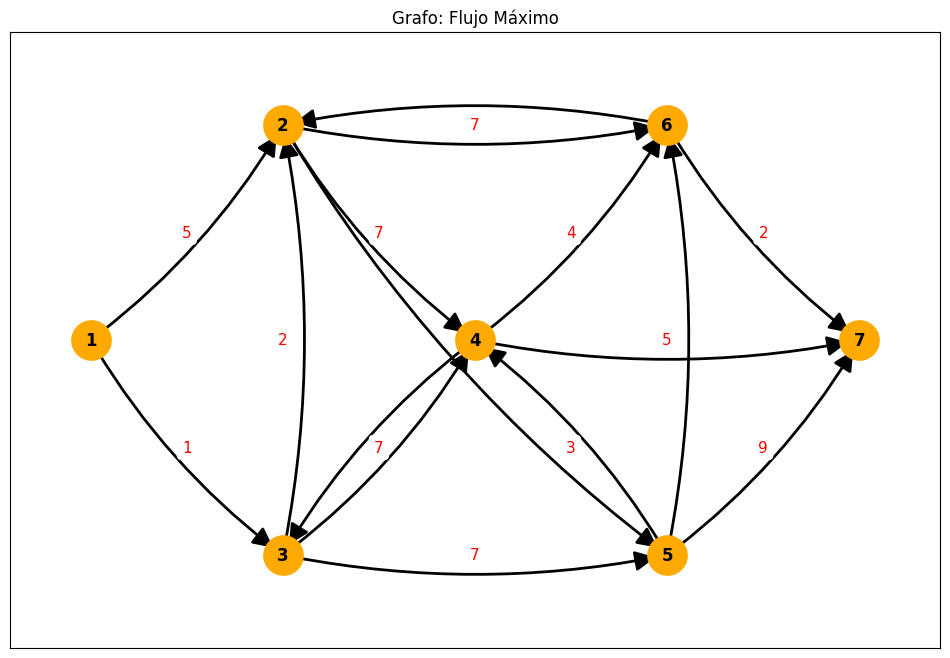

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

list_edges = [
    (1, 2, 5),
    (1, 3, 1),
    (2, 4, 7),
    (2, 5, 1),
    (2, 6, 6),  # Flecha superior (ida)
    (3, 2, 2),
    (3, 4, 6),
    (3, 5, 7),
    (4, 3, 7),
    (4, 6, 4),
    (4, 7, 6),
    (5, 4, 3),
    (5, 6, 5),
    (5, 7, 9),
    (6, 2, 7),  # Flecha superior (vuelta)
    (6, 7, 2),
]

G.add_weighted_edges_from(list_edges, weight='capacidad')

pos = {
    1: (0, 0.5),
    2: (1, 1),
    3: (1, 0),
    4: (2, 0.5),
    5: (3, 0),
    6: (3, 1),
    7: (4, 0.5)
}

plt.figure(figsize=(12, 8))

nx.draw_networkx_nodes(G, pos, node_color="#FFAA00", node_size=800)
nx.draw_networkx_labels(G, pos, font_weight='bold')


nx.draw_networkx_edges(G, pos, edge_color='black', arrowsize=30,
                       connectionstyle='arc3, rad=0.1', width=2.0)

edge_labels = nx.get_edge_attributes(G, 'capacidad')

nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels,
                             font_color="red", font_size=11,
                             label_pos=0.5, rotate=False)

plt.title("Grafo: Flujo Máximo")
plt.show()

### <font color="cyan"> RUTA MAS CORTA.

Para encontrar la ruta más corta utilizamos directamente la funcion de networkx

`ruta = nx.shortest_path(
    G,
    source=1,
    target=7,
    weight="weight"
)`

Esta es la parte principal del programa. `nx.shortest_path()` busca la ruta de menor costo entre dos nodos.

Los parámetros indican:

- G : es la red sobre la que queremos trabajar.

- `source=1` : indica que el recorrido comienza en el nodo 1.

- `target=7` : indica que queremos terminar en el nodo 7.

- `weight="weight"` : le indica a NetworkX que no debe buscar simplemente el camino con menor cantidad de nodos, sino el camino cuyo suma de pesos sea mínima.

**Calcular el costo total**
`distancia = nx.shortest_path_length(
    G,
    source=1,
    target=7,
    weight="weight"
)`

Aquí se utiliza `nx.shortest_path_length()` para obtener el costo total de la ruta más corta.

In [7]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()  # Red dirigida

G.add_nodes_from([1, 2, 3, 4, 5, 6, 7])

arcos = [
    (1, 2, 5),
    (1, 3, 1),
    (1, 5, 4),
    (2, 4, 7),
    (2, 5, 1),
    (2, 6, 6),
    (3, 2, 2),
    (3, 4, 6),
    (3, 5, 7),
    (4, 3, 7),
    (4, 6, 4),
    (4, 7, 6),
    (5, 4, 3),
    (5, 6, 5),
    (5, 7, 9),
    (6, 2, 6),
    (6, 7, 2),
]

G.add_weighted_edges_from(arcos)

# Ruta más corta de 1 a 7
ruta = nx.shortest_path(G, source=1, target=7, weight="weight")

# Distancia/peso total
distancia = nx.shortest_path_length(G, source=1, target=7, weight="weight")

print("Ruta más corta:", ruta)
print("Distancia mínima:", distancia)

Ruta más corta: [1, 3, 2, 6, 7]
Distancia mínima: 11


## <font color="yellow"> EJERCICIO 3.

Para este ejercicio tenemos una red dirigida, la cual podremos graficar haciendo uso de la funcion simple $DiGraph$. Aunque en este caso $DiGraph$ nos servira solamente para añadir mas de 1 capacidad, teniendo $(a,b,c,d)$.

Haremos la misma importacion del nodo, lista como ya mencione y misma forma de dibujar arcos y nodos, lo que cambiara a diferencia de otros ejercicios sera:

**Recorrer los arcos y obtener sus datos**

La instrucción `for u, v, data in G.edges(data=True):` recorre cada arco del grafo. u representa el nodo de origen, v representa el nodo de destino y data contiene los atributos almacenados en ese arco. En este caso, data permite acceder a las cantidades guardadas anteriormente mediante `data["inicio"]` y `data["fin"]`.

**Obtener las coordenadas del origen y destino**

Las instrucciones `x1, y1 = pos[u] y x2, y2 = pos[v]` obtienen las coordenadas de los nodos que forman el arco. x1 y y1 corresponden a las coordenadas del nodo de origen u, mientras que x2 y y2 corresponden a las coordenadas del nodo de destino v. Estas coordenadas son necesarias para calcular dónde colocar cada una de las dos cantidades sobre el arco.

**Definir la posición de la primera cantidad**

La instrucción `t1 = 0.25` establece que la primera cantidad se colocará al 25 % del recorrido entre el origen y el destino. De esta forma, el número correspondiente a inicio queda cerca del nodo de origen.

La expresión `x_inicio = x1 + t1 * (x2 - x1)` calcula la coordenada horizontal donde se colocará la primera cantidad. Básicamente, toma la posición del origen x1 y avanza el 25 % de la distancia existente hasta x2.

La expresión `y_inicio = y1 + t1 * (y2 - y1)` realiza el mismo procedimiento anterior, pero para la coordenada vertical. De esta manera, x_inicio y y_inicio forman el punto exacto sobre el arco donde aparecerá la cantidad inicial.

Y de la misma forma conseguimos la cantidad 2, solo cambiando los valores.

**Mostrar la cantidad inicial**

La función `plt.text(x_inicio, y_inicio, str(data["inicio"]), fontsize=13, ha="center", va="center", bbox=dict(facecolor="white", edgecolor="none", pad=1))` coloca en la gráfica la cantidad correspondiente al origen del arco. `x_inicio` y `y_inicio` indican su posición, mientras que `str(data["inicio"])` convierte el valor almacenado en texto para poder mostrarlo. fontsize=13 establece el tamaño de la letra, y ha="center" junto con va="center" centra el texto horizontal y verticalmente respecto al punto indicado.

El parámetro bbox crea un pequeño recuadro detrás del número. `facecolor="white"` hace que el fondo sea blanco, edgecolor="none" elimina el borde del recuadro y pad=1 establece un pequeño espacio entre el texto y el fondo.

**Mostrar la cantidad final**

La segunda llamada a `plt.text()` funciona de la misma manera, pero utiliza `x_fin` y `y_fin` para colocar el valor de `data["fin"]`. Por lo tanto, cada arco termina mostrando dos cantidades independientes, una cerca del origen y otra cerca del destino.

**Ocultar los ejes**

La instrucción `plt.axis("off")` desactiva la visualización de los ejes X y Y. Esto permite que solamente se muestre el grafo, sin las coordenadas, números de los ejes ni líneas de referencia.

**Ajustar automáticamente la distribución**

La instrucción `plt.tight_layout()` ajusta automáticamente los elementos de la figura para aprovechar mejor el espacio disponible. Esto ayuda a evitar que los nodos, números o etiquetas queden demasiado cerca de los bordes de la figura.

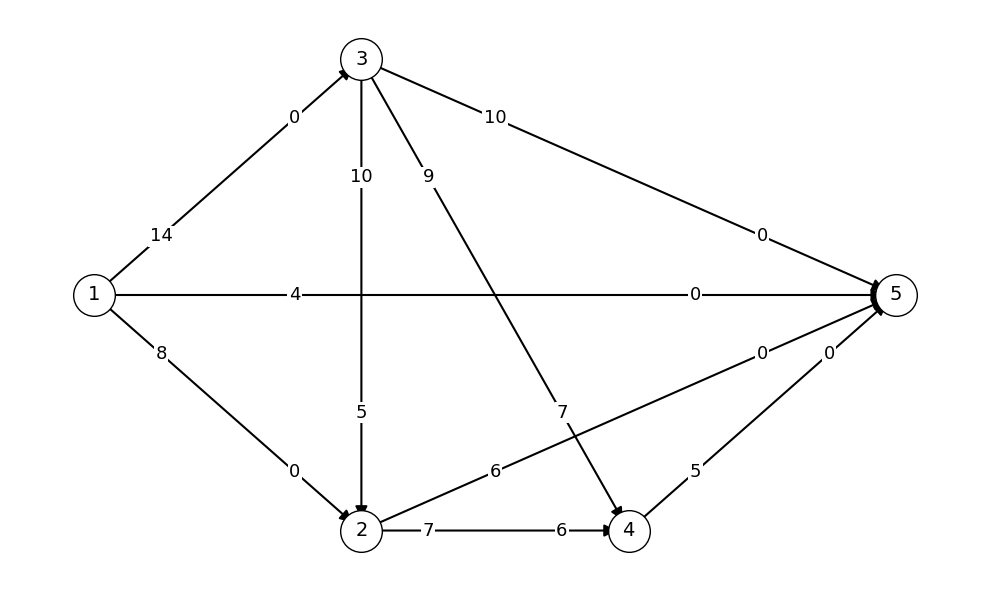

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

arcos = [
    (1, 3, 14, 0),
    (1, 5, 4, 0),
    (1, 2, 8, 0),
    (3, 2, 10, 5),
    (3, 4, 9, 7),
    (3, 5, 10, 0),
    (2, 4, 7, 6),
    (2, 5, 6, 0),
    (4, 5, 5, 0),
]

for u, v, a, b in arcos:
    G.add_edge(u, v, inicio=a, fin=b)

pos = {
    1: (0, 1),
    2: (1, 0),
    3: (1, 2),
    4: (2, 0),
    5: (3, 1),
}

plt.figure(figsize=(10, 6))

nx.draw_networkx_nodes(
    G, pos,
    node_color="white",
    edgecolors="black",
    node_size=900
)

nx.draw_networkx_labels(
    G, pos,
    font_size=14
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=18,
    width=1.5,
    connectionstyle="arc3,rad=0.0"
)

for u, v, data in G.edges(data=True):

    x1, y1 = pos[u]
    x2, y2 = pos[v]

    t1 = 0.25
    x_inicio = x1 + t1 * (x2 - x1)
    y_inicio = y1 + t1 * (y2 - y1)

    t2 = 0.75
    x_fin = x1 + t2 * (x2 - x1)
    y_fin = y1 + t2 * (y2 - y1)

    plt.text(
        x_inicio, y_inicio,
        str(data["inicio"]),
        fontsize=13,
        ha="center",
        va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=1)
    )

    plt.text(
        x_fin, y_fin,
        str(data["fin"]),
        fontsize=13,
        ha="center",
        va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=1)
    )

plt.axis("off")
plt.tight_layout()
plt.show()

### <font color="cyan"> FLUJO MAXIMO.

**Cálculo del flujo máximo**

La instrucción flujo, `datos = nx.maximum_flow(G, 1, 5)` utiliza el algoritmo de flujo máximo proporcionado por NetworkX para encontrar cuánto flujo puede enviarse desde el nodo 1 hasta el nodo 5. La función `maximum_flow()` recibe tres argumentos principales: G, que es el grafo sobre el que se realizará el cálculo; 1, que representa el nodo de origen; y 5, que representa el nodo destino. La función devuelve dos resultados: el primero se almacena en flujo y contiene el valor total del flujo máximo, mientras que el segundo se almacena en datos y contiene un diccionario con el flujo que terminó utilizando cada arco.

**Impresión del flujo máximo**

La instrucción `print("FLUJO MÁXIMO:", flujo)` muestra en pantalla el valor almacenado en flujo. Este valor representa la cantidad total de unidades que pueden llegar desde el nodo origen hasta el nodo destino respetando las capacidades de todos los arcos.

**Recorrido de los arcos**

El bloque `for u, v in G.edges():` recorre todas las aristas existentes en el grafo G. La función `G.edges()` devuelve las conexiones del grafo y, como se trata de un DiGraph, cada conexión conserva su dirección. En cada iteración, u representa el nodo origen y v representa el nodo destino. Esto permite consultar tanto el flujo calculado para ese arco como su capacidad original.

**Mostrar flujo y capacidad**

La instrucción `print(f"{u} -> {v}: {datos[u][v]}/{G[u][v]['capacity']}")` muestra para cada arco el flujo utilizado y su capacidad máxima en el formato flujo/capacidad. La expresión `datos[u][v]` obtiene el flujo que el algoritmo asignó al arco, mientras que `G[u][v]["capacity"]` recupera la capacidad original almacenada en el grafo. Por ejemplo, si el resultado es 1 -> 3: 8/14, significa que por el arco de 1 a 3 circulan 8 unidades de flujo de las 14 que como máximo puede soportar.

FLUJO MÁXIMO: 25

Flujos finales:
1 -> 3: 13/14
1 -> 5: 4/4
1 -> 2: 8/8
3 -> 2: 0/10
3 -> 4: 3/9
3 -> 5: 10/10
2 -> 4: 2/7
2 -> 5: 6/6
4 -> 5: 5/5


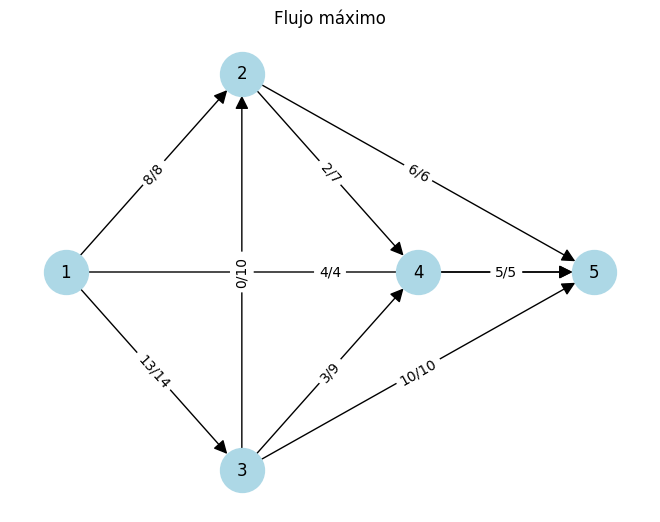

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

arcos = [
    (1, 3, 14),
    (1, 5, 4),
    (1, 2, 8),
    (3, 2, 10),
    (3, 4, 9),
    (3, 5, 10),
    (2, 4, 7),
    (2, 5, 6),
    (4, 5, 5),
]

G = nx.DiGraph()
G.add_weighted_edges_from(arcos, weight="capacity")


flujo, datos = nx.maximum_flow(G, 1, 5)

print("FLUJO MÁXIMO:", flujo)

print("\nFlujos finales:")

for u, v in G.edges():
    print(f"{u} -> {v}: {datos[u][v]}/{G[u][v]['capacity']}")


pos = {
    1: (0, 2),
    2: (2, 3),
    3: (2, 1),
    4: (4, 2),
    5: (6, 2)
}

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1000,
    node_color="lightblue",
    arrows=True,
    arrowsize=20
)

etiquetas = {
    (u, v): f"{datos[u][v]}/{G[u][v]['capacity']}"
    for u, v in G.edges()
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=etiquetas,
    font_size=10
)

plt.title("Flujo máximo")
plt.axis("off")
plt.show()